[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_pairs/BA_L7_pairs.ipynb)

# BA_L7_pairs: Illustration of a correlation of 0.82: BTC-ETH and BTC-TRX

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Scatter plots of daily log returns of Bitcoin against Ether (highest correlation with BTC, 0.82) and against Tron (lowest, 0.52), January 2021 - October 2026 (EODHD), with least-squares lines, the share of days with the same sign and the Mantegna distance.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Data

Daily closes of 19 coins from EODHD (course repository, `data/market`), 1 January 2021 to 23 October 2026.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [5]:
COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()           # daily log returns in %
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


### Method

For each pair the cell prints the Pearson correlation $\rho$, the least-squares slope of the second coin's return on Bitcoin's return,
the share of days on which both returns have the same sign, $\rho^2$ (the share of the second coin's variance explained by a line in BTC)
and the Mantegna distance $d = \sqrt{2(1 - \rho)}$ used for the minimum spanning tree.

BTC-ETH: correlation 0.82, slope 1.11, same sign on 82% of days, rho^2 = 0.68, distance d = 0.60
BTC-TRX: correlation 0.52, slope 0.67, same sign on 69% of days, rho^2 = 0.27, distance d = 0.98


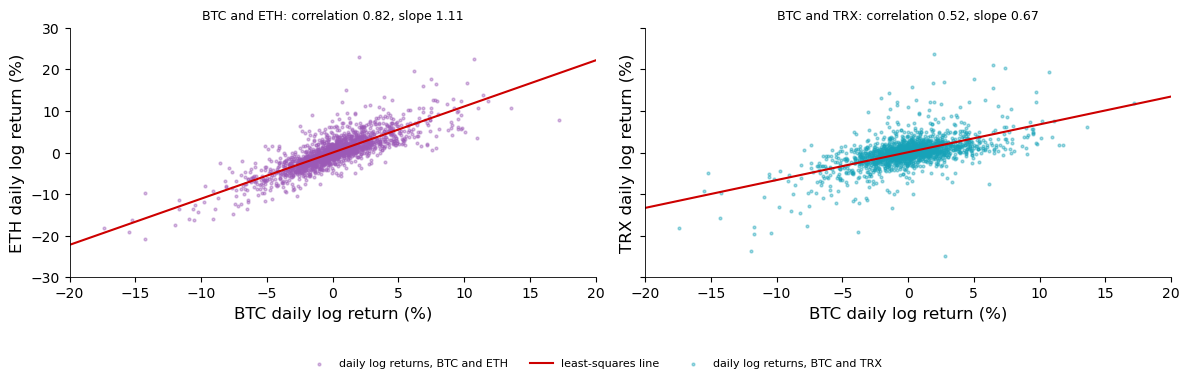

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True, sharey=True)
for k, (b, col) in enumerate([('ETH', ETH), ('TRX', TEAL)]):
    x, y = R['BTC'], R[b]
    slope, icpt = np.polyfit(x, y, 1)
    rho = x.corr(y)
    print(f'BTC-{b}: correlation {rho:.2f}, slope {slope:.2f}, same sign on {100 * (np.sign(x) == np.sign(y)).mean():.0f}% of days, '
          f'rho^2 = {rho ** 2:.2f}, distance d = {np.sqrt(2 * (1 - rho)):.2f}')
    ax[k].scatter(x, y, s=4, color=col, alpha=0.4, label=f'daily log returns, BTC and {b}')
    xx = np.linspace(-20, 20, 50)
    ax[k].plot(xx, icpt + slope * xx, color=RED, lw=1.5, label='least-squares line' if k == 0 else None)
    ax[k].set_xlim(-20, 20); ax[k].set_ylim(-30, 30)
    ax[k].set_xlabel('BTC daily log return (%)'); ax[k].set_ylabel(f'{b} daily log return (%)')
    ax[k].set_title(f'BTC and {b}: correlation {rho:.2f}, slope {slope:.2f}', fontsize=9)
slide_fig(fig, 'ba_l7_pairs', 0.1, ncol=3)

**How to read it.** A correlation of 0.82 is a tight cloud along a line: ETH and BTC move in the same direction on most days. At 0.52 the cloud
is wide: BTC explains about a quarter of Tron's daily variance.